# Zusammenführung von Zwift-Fitnessdaten mit DWD-Temperaturdaten

## Ziel des Notebooks
Aufbereitung und Zusammenführung von Zwift-Fitnessdaten mit DWD-Temperaturdaten für die anschließende Analyse.

## Datenquellen
| Datei | Beschreibung |
|---|---|
| `Source_Data/temperaturdaten.csv` | DWD-Station München-Stadt (ID 3379), 10-Minuten-Werte |
| `Dataframes/workouts_per_second.csv` | Sekündliche Messwerte aus den `.fit`-Dateien |
| `Dataframes/session_records.csv` | Aggregatwerte pro Fahrt (Session-Records aus den `.fit`-Dateien) |

## Outputs
| Datei | Beschreibung |
|---|---|
| `merged_data.csv` | Zusammengeführter Datensatz aus Fitness- und Temperaturdaten; Basis für den Großteil der Analyse |
| `session_data_cleaned.csv` | Bereinigte Version von `session_records.csv` |

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [2]:
df_temperature = pd.read_csv("Source_Data/temperaturdaten.csv", encoding="utf-8", sep=";")
df_fitness =  pd.read_csv("Dataframes/workouts_per_second.csv", encoding="utf-8")
df_session = pd.read_csv("Dataframes/session_records.csv", encoding="utf-8")

In [3]:
df_session.columns

Index(['source_file', 'message_type', 'avg_cadence', 'avg_heart_rate',
       'avg_power', 'avg_speed', 'enhanced_avg_speed', 'enhanced_max_speed',
       'event', 'event_group', 'event_type', 'first_lap_index', 'max_cadence',
       'max_heart_rate', 'max_power', 'max_speed', 'message_index', 'nec_lat',
       'nec_long', 'num_laps', 'sport', 'start_position_lat',
       'start_position_long', 'start_time', 'sub_sport', 'swc_lat', 'swc_long',
       'timestamp', 'total_ascent', 'total_calories', 'total_cycles',
       'total_descent', 'total_distance', 'total_elapsed_time',
       'total_fat_calories', 'total_timer_time', 'total_training_effect',
       'trigger', 'unknown_193'],
      dtype='str')

In [4]:
df_session.dropna(axis=1, how='all', inplace = True)
df_session.describe(include = 'all')

,source_file,message_type,avg_cadence,avg_heart_rate,avg_power,avg_speed,enhanced_avg_speed,enhanced_max_speed,event,event_group,...,total_calories,total_cycles,total_descent,total_distance,total_elapsed_time,total_fat_calories,total_timer_time,total_training_effect,trigger,unknown_193
count,305,305,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305,305.0,...,305.000000,305.0,305.0,305.000000,305.000000,305.0,305.000000,305.0,305,12.000000
unique,305,1,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
top,2026-01-10-13-32-12.fit,session,NaN,NaN,NaN,NaN,NaN,NaN,session,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,activity_end,NaN
freq,1,305,NaN,NaN,NaN,NaN,NaN,NaN,305,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305,NaN
mean,NaN,NaN,54.016393,86.524590,86.665574,4.808128,4.808128,10.998026,NaN,0.0,...,239.527869,0.0,0.0,13510.495639,2008.318033,0.0,1992.947541,0.0,NaN,47.500000
std,NaN,NaN,36.556684,64.541961,61.050181,3.360984,3.360984,8.147761,NaN,0.0,...,257.900136,0.0,0.0,14528.046984,2186.615307,0.0,2174.874122,0.0,NaN,16.025548
min,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.0,...,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,NaN,20.000000
25%,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.0,...,0.000000,0.0,0.0,0.000000,1.000000,0.0,0.000000,0.0,NaN,40.000000
50%,NaN,NaN,76.000000,123.000000,113.000000,6.126000,6.126000,13.314000,NaN,0.0,...,140.000000,0.0,0.0,8431.430000,1353.000000,0.0,1314.000000,0.0,NaN,50.000000
75%,NaN,NaN,82.000000,135.000000,134.000000,7.585000,7.585000,16.687000,NaN,0.0,...,390.000000,0.0,0.0,23294.210000,3113.000000,0.0,3114.000000,0.0,NaN,52.500000


In [5]:
# Identify columns with only one unique value
single_value_columns = df_session.columns[df_session.nunique() == 1]

# Drop those columns from the DataFrame
df_session.drop(columns=single_value_columns, inplace=True)

df_session.describe(include = 'all')

,source_file,avg_cadence,avg_heart_rate,avg_power,avg_speed,enhanced_avg_speed,enhanced_max_speed,max_cadence,max_heart_rate,max_power,max_speed,num_laps,start_time,timestamp,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time,unknown_193
count,305,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,216,305,305.000000,305.000000,305.000000,305.000000,305.000000,12.000000
unique,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,216,305,NaN,NaN,NaN,NaN,NaN,NaN
top,2026-01-10-13-32-12.fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-01-10 12:33:03,2026-01-10 12:51:14,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,54.016393,86.524590,86.665574,4.808128,4.808128,10.998026,69.140984,104.540984,219.842623,10.998026,6.462295,NaN,NaN,139.701639,239.527869,13510.495639,2008.318033,1992.947541,47.500000
std,NaN,36.556684,64.541961,61.050181,3.360984,3.360984,8.147761,46.480929,78.502551,195.029809,8.147761,9.870513,NaN,NaN,208.273541,257.900136,14528.046984,2186.615307,2174.874122,16.025548
min,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
25%,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,1.000000,0.000000,40.000000
50%,NaN,76.000000,123.000000,113.000000,6.126000,6.126000,13.314000,95.000000,146.000000,205.000000,13.314000,1.000000,NaN,NaN,64.000000,140.000000,8431.430000,1353.000000,1314.000000,50.000000
75%,NaN,82.000000,135.000000,134.000000,7.585000,7.585000,16.687000,102.000000,164.000000,314.000000,16.687000,10.000000,NaN,NaN,198.000000,390.000000,23294.210000,3113.000000,3114.000000,52.500000


Entferne Spalten die Duplikate sind (enhanced_avg_speed, enhanced_max_speed) oder nicht relevant.

In [6]:
df_session.drop(columns=['enhanced_avg_speed','enhanced_max_speed','num_laps','unknown_193'], inplace=True)
df_session.describe(include = 'all')

,source_file,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,start_time,timestamp,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time
count,305,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,305.000000,216,305,305.000000,305.000000,305.000000,305.000000,305.000000
unique,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,216,305,NaN,NaN,NaN,NaN,NaN
top,2026-01-10-13-32-12.fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-01-10 12:33:03,2026-01-10 12:51:14,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,54.016393,86.524590,86.665574,4.808128,69.140984,104.540984,219.842623,10.998026,NaN,NaN,139.701639,239.527869,13510.495639,2008.318033,1992.947541
std,NaN,36.556684,64.541961,61.050181,3.360984,46.480929,78.502551,195.029809,8.147761,NaN,NaN,208.273541,257.900136,14528.046984,2186.615307,2174.874122
min,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.000000,1.000000,0.000000
50%,NaN,76.000000,123.000000,113.000000,6.126000,95.000000,146.000000,205.000000,13.314000,NaN,NaN,64.000000,140.000000,8431.430000,1353.000000,1314.000000
75%,NaN,82.000000,135.000000,134.000000,7.585000,102.000000,164.000000,314.000000,16.687000,NaN,NaN,198.000000,390.000000,23294.210000,3113.000000,3114.000000


In [7]:
df_session.head(5)

,source_file,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,start_time,timestamp,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time
0,2026-01-10-13-32-12.fit,78,0,75,5.773,99,0,189,11.254,2026-01-10 12:33:03,2026-01-10 12:51:14,16,69,5606.35,970.0,971.0
1,2026-01-10-13-58-48.fit,0,0,0,0.000,0,0,0,0.000,NaN,2026-01-10 12:59:20,0,0,0.00,1.0,0.0
2,2026-01-10-13-59-21.fit,53,0,75,4.594,88,0,485,13.917,2026-01-10 13:14:42,2026-01-10 14:45:36,199,403,24694.82,5374.0,5375.0
3,2026-01-10-17-37-48.fit,64,0,92,6.107,92,0,324,16.685,2026-01-10 16:38:43,2026-01-10 17:10:21,85,112,7780.89,1289.0,1274.0
4,2026-01-11-11-16-39.fit,44,0,76,5.676,66,0,202,11.243,2026-01-11 10:17:25,2026-01-11 10:45:31,56,96,7458.55,1415.0,1314.0


`timestamp` ist im Datensatz das Ende der Fahrt.

In [8]:
df_session.rename(columns={"timestamp": "end_time"}, inplace=True)

In [9]:
cols = df_session.columns.tolist()
cols.remove("start_time")
cols.remove("end_time")
cols.insert(1, "start_time")
cols.insert(2, "end_time")

df_session = df_session[cols]

In [10]:
df_session.sample(5)

,source_file,start_time,end_time,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time
217,2026-07-06-16-26-04.fit,2026-07-06 14:27:45,2026-07-06 16:24:30,82,129,131,7.524,96,150,151,15.973,407,855,51311.82,6970.0,6819.0
110,2026-04-01-19-53-42.fit,2026-04-01 17:56:13,2026-04-01 18:35:35,87,117,87,4.700,111,135,239,15.959,144,190,10730.47,2282.0,2283.0
25,2026-01-27-17-58-16.fit,2026-01-27 16:58:56,2026-01-27 17:59:43,80,142,120,7.083,101,173,473,14.909,176,416,25697.54,3627.0,3628.0
116,2026-04-08-13-46-06.fit,NaN,2026-04-08 11:46:17,0,0,0,0.000,0,0,0,0.000,0,0,0.00,1.0,0.0
135,2026-04-24-17-02-39.fit,2026-04-24 15:03:26,2026-04-24 15:22:12,74,116,97,5.650,93,151,249,19.860,66,102,6244.07,1115.0,1105.0


In [11]:
df_session.end_time.dtype

<StringDtype(storage='python', na_value=nan)>

FIT-Dateien speichern Zeitstempel in UTC. Für manche Auswertungen möchte ich aber die lokale Zeit verwenden.

In [12]:
df_session["start_time"] = pd.to_datetime(df_session["start_time"], utc=True)
df_session["end_time"] = pd.to_datetime(df_session["end_time"], utc=True)

In [13]:
df_session["start_time_Berlin"] = df_session["start_time"].dt.tz_convert("Europe/Berlin")
df_session["end_time_Berlin"] = df_session["end_time"].dt.tz_convert("Europe/Berlin")

cols = df_session.columns.tolist()
cols.remove("start_time_Berlin")
cols.remove("end_time_Berlin")
cols.insert(3, "start_time_Berlin")
cols.insert(4, "end_time_Berlin")

df_session = df_session[cols]                                                                     

In [14]:
df_session.sample(5)

,source_file,start_time,end_time,start_time_Berlin,end_time_Berlin,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time
204,2026-06-22-20-00-29.fit,2026-06-22 18:04:52+00:00,2026-06-22 19:17:42+00:00,2026-06-22 20:04:52+02:00,2026-06-22 21:17:42+02:00,79,125,116,7.797,94,147,141,15.402,66,365,25678.40,4327.0,3293.0
18,2026-01-22-15-03-58.fit,2026-01-22 14:14:20+00:00,2026-01-22 15:14:24+00:00,2026-01-22 15:14:20+01:00,2026-01-22 16:14:24+01:00,74,155,121,6.657,104,178,437,16.841,272,442,24001.02,3604.0,3605.0
138,2026-04-27-18-49-48.fit,2026-04-27 17:00:54+00:00,2026-04-27 17:29:48+00:00,2026-04-27 19:00:54+02:00,2026-04-27 19:29:48+02:00,85,126,117,8.124,99,182,298,17.481,113,238,14096.35,1734.0,1735.0
197,2026-06-08-13-12-01.fit,2026-06-08 11:14:30+00:00,2026-06-08 12:04:11+00:00,2026-06-08 13:14:30+02:00,2026-06-08 14:04:11+02:00,84,156,155,8.992,104,203,698,14.365,144,452,26814.39,2981.0,2982.0
137,2026-04-27-18-49-34.fit,NaT,2026-04-27 16:49:47+00:00,NaT,2026-04-27 18:49:47+02:00,0,0,0,0.000,0,0,0,0.000,0,0,0.00,1.0,0.0


0 ist in FIT-Dateien der Default-Wert für nicht vorhandene Herzfrequenzdaten (z. B. Fahrten ohne Brustgurt) und wird zu `NaN` konvertiert, damit Mittelwerte nicht verfälscht werden.

In [15]:
df_session[["avg_heart_rate", "max_heart_rate"]] = df_session[["avg_heart_rate", "max_heart_rate"]].replace(0, np.nan)

In [16]:
df_session[df_session.start_time.isna()].describe()

,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time
count,89.0,0.0,89.0,89.0,89.0,0.0,89.0,89.0,89.0,89.000000,89.0,89.0,89.0
mean,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.022472,0.0,1.0,0.0
std,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.212000,0.0,0.0,0.0
min,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.000000,0.0,1.0,0.0
25%,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.000000,0.0,1.0,0.0
50%,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.000000,0.0,1.0,0.0
75%,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.000000,0.0,1.0,0.0
max,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,2.000000,0.0,1.0,0.0


Die Fitnessdateien enthalten für jede Sekunde eines Workouts einen Datenpunkt. Dabei werden zahlreiche Messwerte in unterschiedlichen Spalten gespeichert. Einige dieser Spalten werden von Zwift jedoch nicht befüllt und enthalten daher keine relevanten Daten.

Im Folgenden wird zunächst ein kurzer Überblick über die vorhandenen Spalten gegeben.


In [17]:
df_fitness.describe()

,accumulated_power,activity_type,altitude,ball_speed,cadence,cadence256,calories,combined_pedal_smoothness,compressed_accumulated_power,compressed_speed_distance,...,time128,time_from_course,total_cycles,total_hemoglobin_conc,total_hemoglobin_conc_max,total_hemoglobin_conc_min,vertical_oscillation,vertical_speed,zone,unknown_139
count,0.0,0.0,607849.000000,0.0,607849.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,91.950694,NaN,78.421180,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,164.489701,NaN,19.177994,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,-6.400000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,13.000000,NaN,76.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,30.400000,NaN,83.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,89.400000,NaN,87.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,1543.000000,NaN,141.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
df_fitness.count() == 0

source_file                         False
message_type                        False
accumulated_power                    True
activity_type                        True
altitude                            False
ball_speed                           True
cadence                             False
cadence256                           True
calories                             True
combined_pedal_smoothness            True
compressed_accumulated_power         True
compressed_speed_distance            True
core_data_quality                    True
core_reserved                        True
cycle_length                         True
cycles                               True
device_index                         True
distance                             True
enhanced_altitude                   False
enhanced_speed                      False
fractional_cadence                   True
gps_accuracy                         True
grade                                True
heart_rate                        

Spalten, die Zwift nicht befüllt hat, werden gelöscht.

In [19]:
df_fitness.dropna(axis=1, how='all', inplace = True)
df_fitness.head()

,source_file,message_type,altitude,cadence,enhanced_altitude,enhanced_speed,heart_rate,position_lat,position_long,power,speed_1s,target_power,timestamp
0,2026-01-10-13-32-12.fit,record,5.0,45,5.0,0.930,0,-138857456,1991775616,43,"(None, None, None, None, None)",50,2026-01-10 12:33:03
1,2026-01-10-13-32-12.fit,record,5.0,45,5.0,1.015,0,-138857440,1991775616,43,"(None, None, None, None, None)",50,2026-01-10 12:33:04
2,2026-01-10-13-32-12.fit,record,5.0,50,5.0,1.549,0,-138857312,1991775616,45,"(None, None, None, None, None)",50,2026-01-10 12:33:05
3,2026-01-10-13-32-12.fit,record,5.0,52,5.0,2.009,0,-138857104,1991775744,49,"(None, None, None, None, None)",50,2026-01-10 12:33:06
4,2026-01-10-13-32-12.fit,record,4.8,53,4.8,2.398,0,-138856880,1991775744,50,"(None, None, None, None, None)",50,2026-01-10 12:33:07


Die Spalte `message_type` wurde nur für die Filterung der Rohdateien benötigt und kann gelöscht werden.

In [20]:
df_fitness = df_fitness.drop('message_type', axis=1)

- `enhanced_altitude` und `altitude` sind identisch und damit redundant.
- `speed_1s` enthält nur Tupel aus `None` und wird von Zwift nicht befüllt.

In [21]:
print(df_fitness[df_fitness['altitude'] != df_fitness['enhanced_altitude']])
print(df_fitness['speed_1s'].unique())

Empty DataFrame
Columns: [source_file, altitude, cadence, enhanced_altitude, enhanced_speed, heart_rate, position_lat, position_long, power, speed_1s, target_power, timestamp]
Index: []
<StringArray>
['(None, None, None, None, None)']
Length: 1, dtype: str


In [22]:
df_fitness.drop(columns = ['enhanced_altitude', 'speed_1s'], inplace = True, errors='ignore')
df_fitness.head()

,source_file,altitude,cadence,enhanced_speed,heart_rate,position_lat,position_long,power,target_power,timestamp
0,2026-01-10-13-32-12.fit,5.0,45,0.930,0,-138857456,1991775616,43,50,2026-01-10 12:33:03
1,2026-01-10-13-32-12.fit,5.0,45,1.015,0,-138857440,1991775616,43,50,2026-01-10 12:33:04
2,2026-01-10-13-32-12.fit,5.0,50,1.549,0,-138857312,1991775616,45,50,2026-01-10 12:33:05
3,2026-01-10-13-32-12.fit,5.0,52,2.009,0,-138857104,1991775744,49,50,2026-01-10 12:33:06
4,2026-01-10-13-32-12.fit,4.8,53,2.398,0,-138856880,1991775744,50,50,2026-01-10 12:33:07


altitude und position sind auch erst mal nicht interessant.

In [23]:
df_fitness = df_fitness.drop(columns = ['altitude', 'position_lat', 'position_long'])

In [24]:
# Get source_file values from df_session where start_time is NaT
missing_start_time_files = df_session.loc[df_session['start_time'].isna(), 'source_file']

# Filter df_fitness for rows matching those source_file values
matching_rows = df_fitness[df_fitness['source_file'].isin(missing_start_time_files)]

matching_rows

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,timestamp


Es gibt also keine Einträge für Fahrten ohne Startzeit. Ich vermute, dass es sich um Fahrten handelt, bei denen ich an den Start eines Rennens gesprungen bin und es wieder verlassen habe, bevor es startet. Das kommt tatsächlich häufiger vor. Wir können daher alle Fahrten ohne Startzeit löschen.

In [25]:
df_session.dropna(subset=["start_time"], inplace=True)
df_session.describe(include='all')

,source_file,start_time,end_time,start_time_Berlin,end_time_Berlin,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time
count,216,216,216,216,216,216.000000,199.000000,216.000000,216.000000,216.00000,199.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000,216.000000
unique,216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2026-01-10-13-32-12.fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2026-05-13 04:36:40.611111+00:00,2026-05-13 05:24:46.398148+00:00,2026-05-13 06:36:40.611111+02:00,2026-05-13 07:24:46.398148+02:00,76.273148,132.613065,122.375000,6.789255,97.62963,160.226131,310.425926,15.529620,197.263889,338.212963,19077.320231,2835.407407,2814.115741
min,NaN,2026-01-10 12:33:03+00:00,2026-01-10 12:51:14+00:00,2026-01-10 13:33:03+01:00,2026-01-10 13:51:14+01:00,0.000000,81.000000,0.000000,0.348000,0.00000,81.000000,0.000000,1.375000,0.000000,0.000000,2.430000,0.000000,1.000000
25%,NaN,2026-03-04 18:43:48.500000+00:00,2026-03-04 18:57:21.500000+00:00,2026-03-04 19:43:48.500000+01:00,2026-03-04 19:57:21.500000+01:00,74.000000,123.500000,109.000000,5.845750,94.00000,147.500000,196.000000,12.700500,53.500000,129.000000,7494.325000,1171.750000,1144.000000
50%,NaN,2026-05-04 04:33:08+00:00,2026-05-04 05:40:01+00:00,2026-05-04 06:33:08+02:00,2026-05-04 07:40:01+02:00,79.000000,131.000000,126.500000,7.030000,99.00000,158.000000,251.000000,15.753500,136.000000,293.500000,16362.450000,2463.500000,2464.500000
75%,NaN,2026-07-12 07:52:49+00:00,2026-07-12 09:43:39.500000+00:00,2026-07-12 09:52:49+02:00,2026-07-12 11:43:39.500000+02:00,83.000000,142.000000,139.000000,7.987750,105.25000,178.500000,411.250000,17.787750,237.500000,464.500000,26841.062500,3722.750000,3671.250000
max,NaN,2026-10-13 18:12:19+00:00,2026-10-13 19:15:00+00:00,2026-10-13 20:12:19+02:00,2026-10-13 21:15:00+02:00,93.000000,182.000000,200.000000,9.431000,141.00000,203.000000,758.000000,29.589000,1539.000000,1027.000000,61755.870000,8792.000000,8793.000000


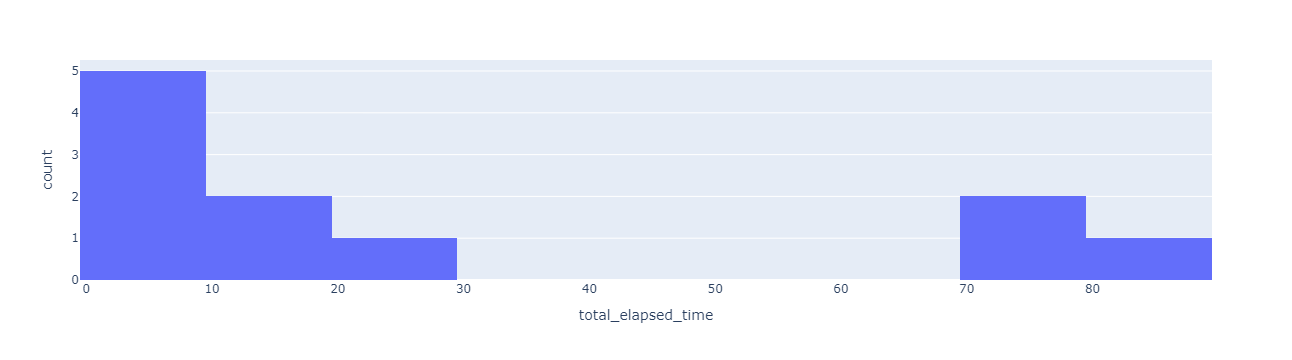

In [26]:
fig = px.histogram(df_session[df_session.total_elapsed_time <= 300], x='total_elapsed_time', nbins=12)
fig.show()

Vielleicht gab es darunter Fahrten, die als Warmup für eine andere Fahrt geschehen sind.

In [27]:
# Extract date part for grouping
df_session['start_date'] = df_session['start_time'].dt.date

# Count sessions per day
sessions_per_day = df_session.groupby('start_date')['start_date'].transform('count')

# Filter: total_elapsed_time <= 100 AND more than one session on that day
result = df_session[
    (df_session['total_elapsed_time'] <= 100) &
    (sessions_per_day > 1)
]

result

,source_file,start_time,end_time,start_time_Berlin,end_time_Berlin,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time,start_date
10,2026-01-15-15-04-23.fit,2026-01-15 14:04:47+00:00,2026-01-15 14:04:51+00:00,2026-01-15 15:04:47+01:00,2026-01-15 15:04:51+01:00,55,NaN,24,2.926,55,NaN,24,1.534,0,0,5.85,1.0,2.0,2026-01-15
51,2026-02-18-19-55-45.fit,2026-02-18 18:55:55+00:00,2026-02-18 18:57:08+00:00,2026-02-18 19:55:55+01:00,2026-02-18 19:57:08+01:00,30,149.0,39,9.378,61,160.0,128,16.382,0,2,693.98,73.0,74.0,2026-02-18
166,2026-05-14-16-58-43.fit,2026-05-14 14:59:21+00:00,2026-05-14 14:59:22+00:00,2026-05-14 16:59:21+02:00,2026-05-14 16:59:22+02:00,38,88.0,120,7.032,38,89.0,120,4.421,0,0,14.06,1.0,2.0,2026-05-14
176,2026-05-19-11-44-30.fit,2026-05-19 09:45:28+00:00,2026-05-19 09:45:29+00:00,2026-05-19 11:45:28+02:00,2026-05-19 11:45:29+02:00,36,93.0,170,8.397,36,93.0,170,4.700,0,0,16.79,1.0,2.0,2026-05-19
182,2026-05-25-09-09-24.fit,2026-05-25 07:10:08+00:00,2026-05-25 07:10:10+00:00,2026-05-25 09:10:08+02:00,2026-05-25 09:10:10+02:00,34,81.0,97,8.827,34,81.0,97,2.390,0,0,8.82,0.0,1.0,2026-05-25
214,2026-07-05-20-41-45.fit,2026-07-05 18:43:53+00:00,2026-07-05 18:46:29+00:00,2026-07-05 20:43:53+02:00,2026-07-05 20:46:29+02:00,31,97.0,71,4.546,63,108.0,225,7.364,0,4,322.76,70.0,71.0,2026-07-05
215,2026-07-05-20-47-08.fit,2026-07-05 18:47:46+00:00,2026-07-05 18:49:31+00:00,2026-07-05 20:47:46+02:00,2026-07-05 20:49:31+02:00,37,85.0,51,2.325,62,92.0,106,4.066,0,0,39.53,16.0,17.0,2026-07-05
229,2026-07-16-17-07-15.fit,2026-07-16 15:14:29+00:00,2026-07-16 15:15:57+00:00,2026-07-16 17:14:29+02:00,2026-07-16 17:15:57+02:00,21,108.0,59,6.759,65,124.0,183,9.081,0,24,601.62,88.0,89.0,2026-07-16
230,2026-07-16-17-16-20.fit,2026-07-16 15:17:22+00:00,2026-07-16 15:17:50+00:00,2026-07-16 17:17:22+02:00,2026-07-16 17:17:50+02:00,21,89.0,24,2.232,58,105.0,135,4.013,0,0,46.89,20.0,21.0,2026-07-16
282,2026-09-22-18-55-54.fit,2026-09-22 16:56:01+00:00,2026-09-22 16:56:17+00:00,2026-09-22 18:56:01+02:00,2026-09-22 18:56:17+02:00,0,NaN,0,0.348,0,NaN,0,2.553,0,0,2.43,6.0,7.0,2026-09-22


Da die höchsten verbrauchten Kalorien bei 24 liegen und dort keine relevant hohe Herzfrequenz gemessen wurde, löschen wir alle diese Zeilen.

In [28]:
# Identify rows to delete in df_session
rows_to_delete = df_session[df_session['total_elapsed_time'] <= 100]

# Get the source_file values of the rows to be deleted
files_to_delete = rows_to_delete['source_file']

# Remove corresponding rows in df_fitness
df_fitness = df_fitness[~df_fitness['source_file'].isin(files_to_delete)]

# Remove the rows from df_session
df_session = df_session[df_session['total_elapsed_time'] > 100]

In [29]:
df_session.describe(include='all')

,source_file,start_time,end_time,start_time_Berlin,end_time_Berlin,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time,start_date
count,205,205,205,205,205,205.00000,191.000000,205.000000,205.000000,205.000000,191.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205
unique,205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,151
top,2026-01-10-13-32-12.fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-01-10
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
mean,NaN,2026-05-11 15:09:56.917073+00:00,2026-05-11 16:00:22.517073+00:00,2026-05-11 17:09:56.917073+02:00,2026-05-11 18:00:22.517073+02:00,78.82439,134.031414,125.687805,6.890405,100.463415,162.476440,321.097561,16.080580,207.848780,356.214634,20092.339659,2986.131707,2963.643902,NaN
min,NaN,2026-01-10 12:33:03+00:00,2026-01-10 12:51:14+00:00,2026-01-10 13:33:03+01:00,2026-01-10 13:51:14+01:00,37.00000,102.000000,47.000000,2.755000,61.000000,125.000000,126.000000,6.128000,0.000000,9.000000,721.940000,303.000000,169.000000,NaN
25%,NaN,2026-03-04 18:23:53+00:00,2026-03-04 18:45:41+00:00,2026-03-04 19:23:53+01:00,2026-03-04 19:45:41+01:00,75.00000,124.000000,112.000000,6.045000,95.000000,149.000000,202.000000,13.297000,63.000000,137.000000,8389.080000,1314.000000,1302.000000,NaN
50%,NaN,2026-04-30 15:41:50+00:00,2026-04-30 16:40:21+00:00,2026-04-30 17:41:50+02:00,2026-04-30 18:40:21+02:00,80.00000,131.000000,127.000000,7.083000,100.000000,159.000000,256.000000,15.820000,144.000000,314.000000,17674.760000,2587.000000,2572.000000,NaN
75%,NaN,2026-07-11 12:34:06+00:00,2026-07-11 12:54:53+00:00,2026-07-11 14:34:06+02:00,2026-07-11 14:54:53+02:00,83.00000,142.000000,140.000000,7.983000,106.000000,179.500000,420.000000,17.998000,253.000000,492.000000,27134.270000,3755.000000,3724.000000,NaN
max,NaN,2026-10-13 18:12:19+00:00,2026-10-13 19:15:00+00:00,2026-10-13 20:12:19+02:00,2026-10-13 21:15:00+02:00,93.00000,182.000000,200.000000,9.431000,141.000000,203.000000,758.000000,29.589000,1539.000000,1027.000000,61755.870000,8792.000000,8793.000000,NaN


In [30]:
df_session.head()

,source_file,start_time,end_time,start_time_Berlin,end_time_Berlin,avg_cadence,avg_heart_rate,avg_power,avg_speed,max_cadence,max_heart_rate,max_power,max_speed,total_ascent,total_calories,total_distance,total_elapsed_time,total_timer_time,start_date
0,2026-01-10-13-32-12.fit,2026-01-10 12:33:03+00:00,2026-01-10 12:51:14+00:00,2026-01-10 13:33:03+01:00,2026-01-10 13:51:14+01:00,78,NaN,75,5.773,99,NaN,189,11.254,16,69,5606.35,970.0,971.0,2026-01-10
2,2026-01-10-13-59-21.fit,2026-01-10 13:14:42+00:00,2026-01-10 14:45:36+00:00,2026-01-10 14:14:42+01:00,2026-01-10 15:45:36+01:00,53,NaN,75,4.594,88,NaN,485,13.917,199,403,24694.82,5374.0,5375.0,2026-01-10
3,2026-01-10-17-37-48.fit,2026-01-10 16:38:43+00:00,2026-01-10 17:10:21+00:00,2026-01-10 17:38:43+01:00,2026-01-10 18:10:21+01:00,64,NaN,92,6.107,92,NaN,324,16.685,85,112,7780.89,1289.0,1274.0,2026-01-10
4,2026-01-11-11-16-39.fit,2026-01-11 10:17:25+00:00,2026-01-11 10:45:31+00:00,2026-01-11 11:17:25+01:00,2026-01-11 11:45:31+01:00,44,NaN,76,5.676,66,NaN,202,11.243,56,96,7458.55,1415.0,1314.0,2026-01-11
5,2026-01-11-12-00-28.fit,2026-01-11 11:01:28+00:00,2026-01-11 11:34:26+00:00,2026-01-11 12:01:28+01:00,2026-01-11 12:34:26+01:00,81,NaN,47,4.061,121,NaN,126,10.133,33,83,7506.25,1913.0,1848.0,2026-01-11


Der DataFrame `df_temperature` enthält Messdaten der Station München-Stadt (`STATIONS_ID`) für den Zeitraum vom 10. Februar 2025 bis zum 13. August 2026.

Jeder Datenpunkt umfasst die innerhalb der letzten zehn Minuten gemessene Höchst- und Tiefsttemperatur. Die Messungen wurden in einer Höhe von 2 Metern sowie 5 Zentimetern über dem Boden durchgeführt.

Das ist natürlich nur eine sehr grobe Annäherung an die Raumtemperatur und wird vermutlich im Sommer eine höhere Rolle spielen als im Winter.

Für die weitere Analyse wird ausschließlich die Lufttemperatur in 2 Metern Höhe verwendet, da diese die Temperatur in meiner Wohnung vermutlich stärker beeinflusst. Die entsprechenden Werte sind in den Spalten `TX_10` (Höchsttemperatur) und `TN_10` (Tiefsttemperatur) enthalten.

Daraus berechnen wir den Mittelwert als angenäherte Durchschnittstemperatur `TM_10` des Zeitraums.

`QN` = Qualitätsniveau, `eor` = End of Record

In [31]:
df_temperature.head()

,STATIONS_ID,MESS_DATUM,QN,PP_10,TT_10,TM5_10,RF_10,TD_10,eor
0,3379,202504120000,3,956.3,7.7,5.9,66.9,1.9,eor
1,3379,202504120010,3,956.1,7.5,5.6,68.0,2.0,eor
2,3379,202504120020,3,955.9,7.4,5.4,68.8,2.0,eor
3,3379,202504120030,3,955.8,7.1,5.1,69.0,1.8,eor
4,3379,202504120040,3,955.8,7.1,5.3,68.9,1.8,eor


In [32]:
df_temperature.drop(columns=['STATIONS_ID','TM5_10', 'TD_10', 'eor'], inplace=True, errors='ignore')
df_temperature

,MESS_DATUM,QN,PP_10,TT_10,RF_10
0,202504120000,3,956.3,7.7,66.9
1,202504120010,3,956.1,7.5,68.0
2,202504120020,3,955.9,7.4,68.8
3,202504120030,3,955.8,7.1,69.0
4,202504120040,3,955.8,7.1,68.9
...,...,...,...,...,...
79195,202610132310,2,965.5,12.3,94.8
79196,202610132320,2,965.6,12.4,94.2
79197,202610132330,2,965.5,12.6,93.5
79198,202610132340,2,965.5,12.6,93.8


In [33]:
df_temperature.info()

<class 'pandas.DataFrame'>
RangeIndex: 79200 entries, 0 to 79199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MESS_DATUM  79200 non-null  int64  
 1     QN        79200 non-null  int64  
 2   PP_10       79200 non-null  float64
 3   TT_10       79200 non-null  float64
 4   RF_10       79200 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 3.0 MB


`QN` scheint Leerzeichen zu enthalten, was die Auswertung erschwert. Deshalb entfernen wir alle möglichen Leerzeichen in den column-Namen.

In [34]:
df_temperature.columns = df_temperature.columns.str.strip()
df_temperature.columns

Index(['MESS_DATUM', 'QN', 'PP_10', 'TT_10', 'RF_10'], dtype='str')

In [35]:
# 1. Datumsformate in echte datetime-Objekte umwandeln
df_temperature['MESS_DATUM'] = pd.to_datetime(df_temperature['MESS_DATUM'], format='%Y%m%d%H%M', utc=True)
df_fitness['timestamp'] = pd.to_datetime(df_fitness['timestamp'], format='%Y-%m-%d %H:%M:%S', utc=True)

# 2. Beide DataFrames nach der Zeit sortieren (Voraussetzung für merge_asof)
df_temperature = df_temperature.sort_values('MESS_DATUM')
df_fitness = df_fitness.sort_values('timestamp')

# 3. merge_asof: findet für jeden fitness-Zeitpunkt den passenden
#    MESS_DATUM-Wert, der >= timestamp ist (forward), 
#    aber maximal 10 Minuten in der Zukunft
df_merged = pd.merge_asof(
    df_fitness,
    df_temperature[['MESS_DATUM', 'QN', 'TT_10', 'PP_10', 'RF_10']],
    left_on='timestamp',
    right_on='MESS_DATUM',
    direction='forward',
    tolerance=pd.Timedelta('10min')
)

In [36]:
df_merged.sample(5)

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,timestamp,MESS_DATUM,QN,TT_10,PP_10,RF_10
549439,2026-09-17-19-27-09.fit,73,13.292,170,212,0,2026-09-17 18:01:19+00:00,2026-09-17 18:10:00+00:00,3,14.4,953.8,68.4
587838,2026-10-05-20-50-10.fit,92,9.828,136,120,0,2026-10-05 19:16:58+00:00,2026-10-05 19:20:00+00:00,3,13.8,962.2,85.7
355884,2026-05-23-17-54-45.fit,78,3.280,146,100,0,2026-05-23 17:26:03+00:00,2026-05-23 17:30:00+00:00,3,25.7,966.1,35.4
47384,2026-01-27-17-58-16.fit,83,10.392,141,154,0,2026-01-27 17:42:42+00:00,2026-01-27 17:50:00+00:00,3,3.4,935.4,73.0
468919,2026-07-16-19-09-52.fit,83,5.075,185,296,0,2026-07-16 17:52:12+00:00,2026-07-16 18:00:00+00:00,3,28.3,955.2,42.0


In [37]:
df_merged.describe(include='all')

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,timestamp,MESS_DATUM,QN,TT_10,PP_10,RF_10
count,607547,607547.000000,607547.000000,607547.000000,607547.000000,607547.000000,607547,607547,607547.000000,607547.000000,607547.000000,607547.000000
unique,205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2026-03-07-18-55-14.fit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,8793,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,78.446983,6.780144,127.633056,124.363305,44.872012,2026-05-12 22:09:56.482703+00:00,2026-05-12 22:14:56.824443+00:00,2.986692,10.712240,954.487688,54.593951
min,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,2026-01-10 12:33:03+00:00,2026-01-10 12:40:00+00:00,2.000000,-999.000000,931.600000,-999.000000
25%,NaN,76.000000,3.723000,120.000000,95.000000,0.000000,2026-03-04 18:34:54.500000+00:00,2026-03-04 18:40:00+00:00,3.000000,6.700000,950.100000,39.500000
50%,NaN,83.000000,7.098000,130.000000,125.000000,0.000000,2026-05-05 14:01:03+00:00,2026-05-05 14:10:00+00:00,3.000000,14.100000,956.600000,56.100000
75%,NaN,87.000000,9.003000,145.000000,151.000000,109.000000,2026-07-11 13:28:55.500000+00:00,2026-07-11 13:30:00+00:00,3.000000,22.400000,960.400000,78.200000
max,NaN,141.000000,29.589000,203.000000,758.000000,400.000000,2026-10-13 19:14:54+00:00,2026-10-13 19:20:00+00:00,3.000000,35.500000,969.700000,100.000000


In [38]:
df_merged[df_merged.QN == 2].describe()

,cadence,enhanced_speed,heart_rate,power,target_power,QN,TT_10,PP_10,RF_10
count,8085.000000,8085.000000,8085.000000,8085.000000,8085.000000,8085.0,8085.000000,8085.000000,8085.000000
mean,82.316883,7.780628,136.782560,142.655040,69.379716,2.0,11.113531,963.685071,77.423191
std,12.199460,3.583840,16.500835,55.123337,66.807283,0.0,2.193924,1.364374,4.358450
min,0.000000,0.000000,83.000000,0.000000,0.000000,2.0,7.300000,961.500000,70.500000
25%,81.000000,5.395000,124.000000,129.000000,0.000000,2.0,8.400000,961.800000,74.700000
50%,85.000000,8.389000,131.000000,130.000000,100.000000,2.0,12.200000,964.500000,75.800000
75%,87.000000,9.749000,152.000000,173.000000,130.000000,2.0,12.900000,964.700000,78.300000
max,97.000000,20.727000,177.000000,477.000000,230.000000,2.0,12.900000,964.900000,90.600000


`QN` steht für das Qualitätsniveau der Temperaturmessung des DWD. Fast alle Einträge haben den Wert 3, was bedeutet: *Die Daten wurden automatisch geprüft und gegebenenfalls automatisch korrigiert.* Die Definition von QN = 2 ist *Die Daten wurden nach individuell festgelegten Kriterien geprüft.* Das reicht uns aus. Die Spalte wird gelöscht, da sie keinen Mehrwert mehr hat.

In [39]:
df_merged = df_merged.drop('QN', axis=1)

Es gibt noch Temperaturwerte, die -999 angeben. Das ist in dem Datensatz der Defaultwert für nicht vorhanden. Wir schauen uns an, wie viele es sind und wann diese auftauchen.

In [40]:
df_merged[df_merged.TT_10 == -999]

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,timestamp,MESS_DATUM,TT_10,PP_10,RF_10
78141,2026-02-05-12-00-37.fit,81,6.444,109,114,0,2026-02-05 11:02:14+00:00,2026-02-05 11:10:00+00:00,-999.0,932.8,-999.0
78142,2026-02-05-12-00-37.fit,81,6.456,109,85,0,2026-02-05 11:02:15+00:00,2026-02-05 11:10:00+00:00,-999.0,932.8,-999.0
78143,2026-02-05-12-00-37.fit,78,6.459,109,79,0,2026-02-05 11:02:16+00:00,2026-02-05 11:10:00+00:00,-999.0,932.8,-999.0
78144,2026-02-05-12-00-37.fit,78,6.465,109,84,0,2026-02-05 11:02:17+00:00,2026-02-05 11:10:00+00:00,-999.0,932.8,-999.0
78145,2026-02-05-12-00-37.fit,78,6.473,108,85,0,2026-02-05 11:02:18+00:00,2026-02-05 11:10:00+00:00,-999.0,932.8,-999.0
...,...,...,...,...,...,...,...,...,...,...,...
80403,2026-02-05-12-00-37.fit,77,2.518,123,73,0,2026-02-05 11:39:56+00:00,2026-02-05 11:40:00+00:00,-999.0,932.6,-999.0
80404,2026-02-05-12-00-37.fit,79,2.507,122,69,0,2026-02-05 11:39:57+00:00,2026-02-05 11:40:00+00:00,-999.0,932.6,-999.0
80405,2026-02-05-12-00-37.fit,80,2.466,121,57,0,2026-02-05 11:39:58+00:00,2026-02-05 11:40:00+00:00,-999.0,932.6,-999.0
80406,2026-02-05-12-00-37.fit,79,2.424,121,62,0,2026-02-05 11:39:59+00:00,2026-02-05 11:40:00+00:00,-999.0,932.6,-999.0


Das ist nur eine Fahrt am 5. Februar. Wir setzen die Temperaturwerte für diese Fahrt auf `NaN`. Es gab auch einige Fahrten, bei denen ich keinen Herzfrequenzmesser getragen habe. Auch hier werden die Default-0-Werte auf `NaN` gesetzt. 
In `target_power` steht ein Wert, wenn ich ein Workout gemacht habe, bei dem man bestimmte Leistungswerte über ein Zeitintervall halten soll. Auch hier werden die Default-0-Werte auf `NaN` gesetzt. Auch die Default-Werte von der relativen Luftfeuchtigkeit werden auf `NaN` gesetzt.

In [41]:
df_merged["heart_rate"] = df_merged["heart_rate"].replace(0, np.nan)
df_merged["TT_10"] = df_merged["TT_10"].replace(-999, np.nan)
df_merged["target_power"] = df_merged["target_power"].replace(0, np.nan)
df_merged["RF_10"] = df_merged["RF_10"].replace(-999, np.nan)

In [42]:
df_merged.describe()

,cadence,enhanced_speed,heart_rate,power,target_power,TT_10,PP_10,RF_10
count,607547.000000,607547.000000,579197.000000,607547.000000,211313.000000,605280.000000,607547.000000,605280.000000
mean,78.446983,6.780144,133.880321,124.363305,129.011731,14.493990,954.487688,58.540054
std,19.139509,3.596772,19.055614,55.517549,36.068797,9.408321,8.432792,21.834348
min,0.000000,0.000000,57.000000,0.000000,25.000000,-5.000000,931.600000,18.400000
25%,76.000000,3.723000,121.000000,95.000000,105.000000,6.900000,950.100000,39.600000
50%,83.000000,7.098000,131.000000,125.000000,129.000000,14.100000,956.600000,56.200000
75%,87.000000,9.003000,146.000000,151.000000,149.000000,22.400000,960.400000,78.300000
max,141.000000,29.589000,203.000000,758.000000,400.000000,35.500000,969.700000,100.000000


Für die Tageszeitauswertung wollen wir auch einen timestamp für die lokale Zeit.

In [43]:
df_merged['timestamp_berlin'] = df_merged['timestamp'].dt.tz_convert('Europe/Berlin')

Für day_of_week nehme ich aber den UTC-timestamp, da ich auch Fahrten, die kurz nach Mitternacht beginnen noch zum Vortag zählen will.

In [44]:
df_merged["day_of_week"] = df_merged.timestamp.dt.day_name()
df_merged.sample(5)

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,timestamp,MESS_DATUM,TT_10,PP_10,RF_10,timestamp_berlin,day_of_week
585186,2026-10-03-16-42-02.fit,83,2.668,123.0,129,NaN,2026-10-03 16:02:12+00:00,2026-10-03 16:10:00+00:00,19.3,967.1,66.3,2026-10-03 18:02:12+02:00,Saturday
603865,2026-10-13-20-03-54.fit,81,8.350,146.0,218,NaN,2026-10-13 18:13:33+00:00,2026-10-13 18:20:00+00:00,12.9,964.3,75.5,2026-10-13 20:13:33+02:00,Tuesday
537052,2026-09-12-14-35-08.fit,82,12.858,116.0,114,115.0,2026-09-12 12:39:20+00:00,2026-09-12 12:40:00+00:00,22.2,962.9,39.9,2026-09-12 14:39:20+02:00,Saturday
547509,2026-09-17-19-14-22.fit,74,6.946,135.0,100,130.0,2026-09-17 17:23:46+00:00,2026-09-17 17:30:00+00:00,16.4,953.7,56.8,2026-09-17 19:23:46+02:00,Thursday
127239,2026-02-22-15-49-22.fit,69,6.788,124.0,150,NaN,2026-02-22 15:06:00+00:00,2026-02-22 15:10:00+00:00,11.6,959.3,69.1,2026-02-22 16:06:00+01:00,Sunday


In [45]:
df_merged["month"] = df_merged.timestamp.dt.month_name()
df_merged.sample(5)

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,timestamp,MESS_DATUM,TT_10,PP_10,RF_10,timestamp_berlin,day_of_week,month
22182,2026-01-18-16-57-58.fit,96,9.916,138.0,65,65.0,2026-01-18 16:12:32+00:00,2026-01-18 16:20:00+00:00,0.2,957.6,89.4,2026-01-18 17:12:32+01:00,Sunday,January
408621,2026-06-17-15-49-01.fit,82,5.488,151.0,170,NaN,2026-06-17 14:32:03+00:00,2026-06-17 14:40:00+00:00,27.6,959.7,44.7,2026-06-17 16:32:03+02:00,Wednesday,June
139939,2026-02-26-20-51-14.fit,77,1.481,122.0,72,125.0,2026-02-26 20:27:56+00:00,2026-02-26 20:30:00+00:00,9.6,962.9,84.1,2026-02-26 21:27:56+01:00,Thursday,February
602477,2026-10-13-19-22-00.fit,88,2.421,128.0,129,130.0,2026-10-13 17:38:34+00:00,2026-10-13 17:40:00+00:00,12.8,964.5,75.8,2026-10-13 19:38:34+02:00,Tuesday,October
245168,2026-03-31-16-43-51.fit,97,10.691,148.0,159,160.0,2026-03-31 15:19:02+00:00,2026-03-31 15:20:00+00:00,5.2,962.3,56.6,2026-03-31 17:19:02+02:00,Tuesday,March


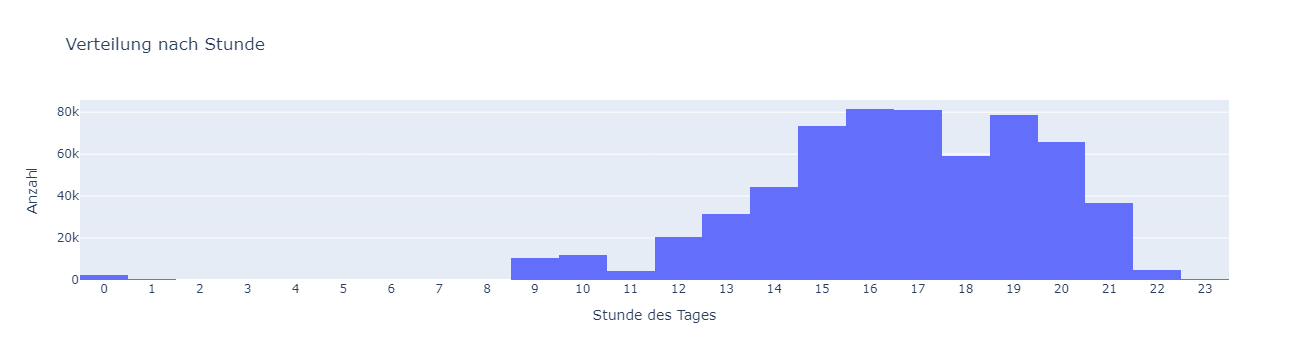

In [46]:
df_merged['hour_utc'] = df_merged['timestamp'].dt.hour
df_merged['hour_berlin'] = df_merged['timestamp_berlin'].dt.hour

fig = px.histogram(df_merged, x='hour_berlin', nbins=24, 
                    title='Verteilung nach Stunde')
fig.update_xaxes(dtick=1, title='Stunde des Tages')
fig.update_yaxes(title='Anzahl')
fig.show()

In [47]:
def plot_ride_intervals(df, start_col="start_time_Berlin", end_col="end_time_Berlin"):
    """Plot ride intervals with day on the y-axis and time-of-day on the x-axis.

    Only days with at least one ride are shown. Start and end times are
    projected onto a common reference date so the x-axis represents
    time-of-day only (no date component).

    Args:
        df: DataFrame containing ride start and end timestamps.
        start_col: Column name with ride start times (datetime).
        end_col: Column name with ride end times (datetime).
    """
    df_plot = df.copy()

    # Day label used for the y-axis (categorical, only existing days appear)
    df_plot["day"] = df_plot[start_col].dt.strftime("%Y-%m-%d")

    # Project start/end times onto a fixed reference date to get a pure
    # time-of-day axis while keeping them as datetime objects for Plotly
    reference_date = pd.Timestamp("2000-01-01")

    def to_time_of_day(series):
        return reference_date + pd.to_timedelta(
            series.dt.hour * 3600
            + series.dt.minute * 60
            + series.dt.second,
            unit="s",
        )

    df_plot["start_tod"] = to_time_of_day(df_plot[start_col])
    df_plot["end_tod"] = to_time_of_day(df_plot[end_col])

    # Handle rides crossing midnight: end time smaller than start time
    # means it wraps into the next reference day
    crosses_midnight = df_plot["end_tod"] < df_plot["start_tod"]
    df_plot.loc[crosses_midnight, "end_tod"] += pd.Timedelta(days=1)

    df_plot = df_plot.sort_values("day")

    num_days = df_plot["day"].nunique()
    # Scale figure height with the number of days, with a sensible minimum
    fig_height = max(600, num_days * 6)

    fig = px.timeline(
        df_plot,
        x_start="start_tod",
        x_end="end_tod",
        y="day",
        title="Ride Intervals by Day (Time of Day)",
    )

    fig.update_layout(height=fig_height)

    fig.update_yaxes(
        autorange="reversed",
        title="Day",
        categoryorder="array",
        categoryarray=sorted(df_plot["day"].unique(), reverse=True),
    )
    fig.update_xaxes(title="Time of day", tickformat="%H:%M")
    fig.show()

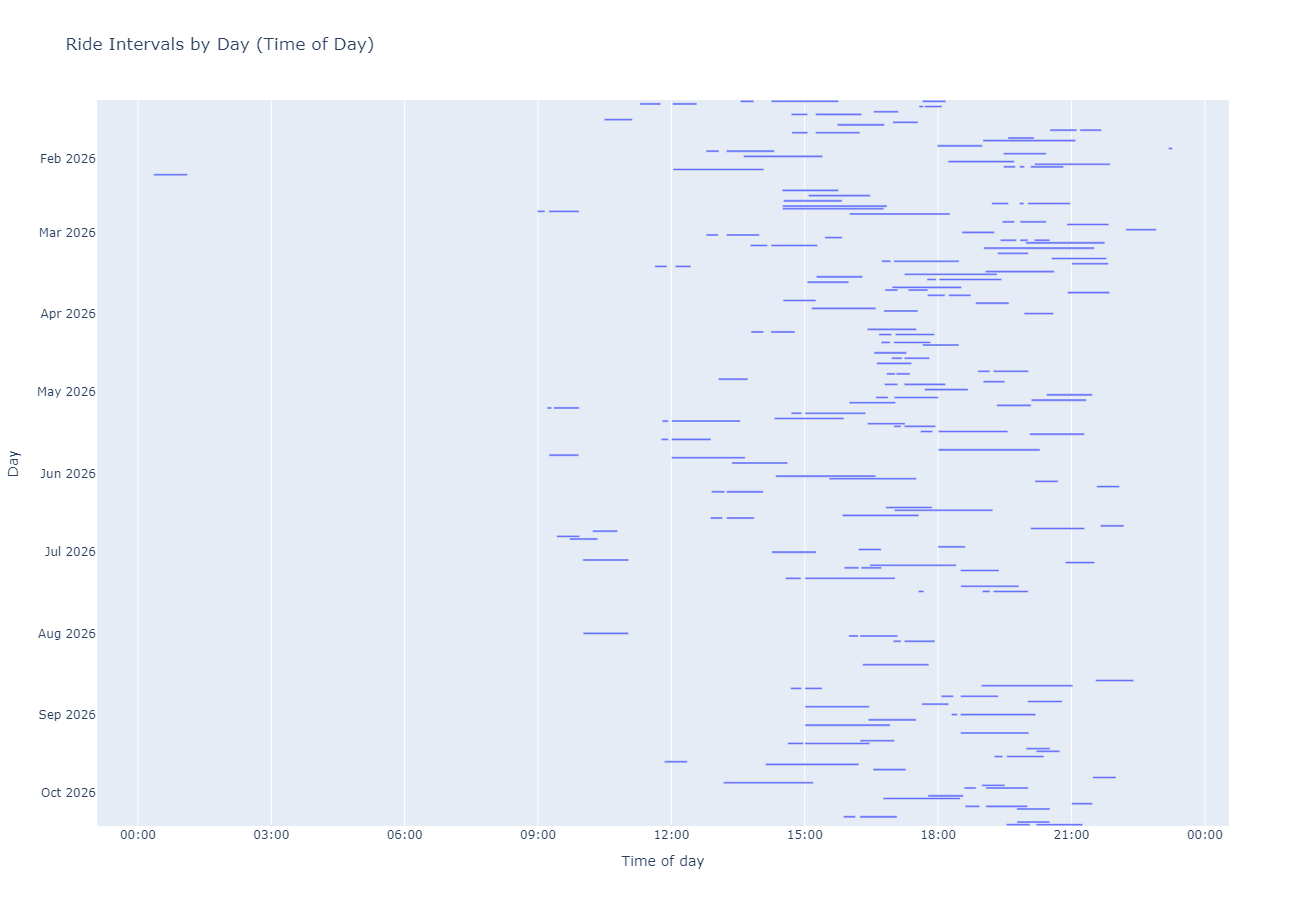

In [48]:
plot_ride_intervals(df_session)

In [49]:
df_merged['time_of_day'] = df_merged['timestamp_berlin'].dt.hour.apply(
    lambda hour:
        'Morning' if 6 <= hour < 12 else
        'Afternoon' if 12 <= hour < 18 else
        'Evening' if 18 <= hour < 24 else
        'Night'
)

In [50]:
df_merged.to_csv("./Dataframes/merged_data.csv", index = False)
df_session.to_csv("./Dataframes/session_data_cleaned.csv", index = False)